In [1]:
import os
import utils
import torch
import pickle
import numpy as np
import matplotlib.pyplot as plt

from torch import nn
from torch.utils.data import DataLoader, Subset
from sklearn.manifold import TSNE

# PARAMETRI

In [2]:
EPOCHS = 10
BATCH_SIZE = 64
LEARNING_RATE = 0.001
DEVICE = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.device('cpu')

print(f"DEVICE: {DEVICE}")

DEVICE: cuda


TRAIN SET shape: torch.Size([60000, 28, 28])
TEST SET shape:  torch.Size([10000, 28, 28])


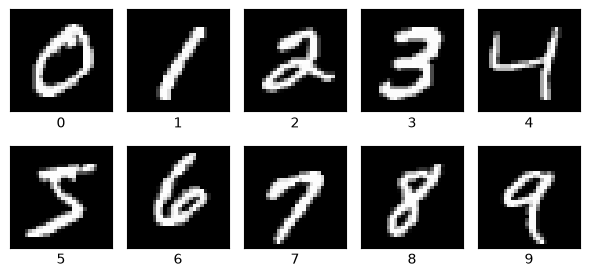

In [3]:
from datasets.datasets import load_MNIST
train_dataset, test_dataset, train_loader, test_loader = load_MNIST(batch_size=BATCH_SIZE, verbose=False)

print(f"TRAIN SET shape: {train_dataset.data.shape}")
print(f"TEST SET shape:  {test_dataset.data.shape}")

plt.figure(figsize=(6, 3))
for c in range(len(train_dataset.classes)):
    idx = (train_dataset.targets == c).nonzero()[0].item()   # primo esempio della classe c
    img, label = train_dataset[idx]
    plt.subplot(2, 5, c + 1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(img.squeeze(), cmap="gray")
    plt.xlabel(label)
plt.tight_layout()
plt.show()

# MODELLO

In [4]:
#Parametri del modello
INPUT_SIZE = 784
H1 = 128
H2 = 64

In [5]:
encoder = nn.Sequential(
    nn.Flatten(),                           # (B, 1, 28, 28) -> (B, 784)
    nn.Linear(INPUT_SIZE, H1),
    nn.ReLU(),
    nn.Linear(H1, H2),
    nn.ReLU(),
)

decoder = nn.Sequential(
    nn.Linear(H2, H1),
    nn.ReLU(),
    nn.Linear(H1, INPUT_SIZE),
    nn.Sigmoid(),
    nn.Unflatten(1, (1, 28, 28)),           # (B, 784) -> (B, 1, 28, 28)
)

autoencoder = nn.Sequential(encoder, decoder).to(DEVICE)

# Versione equivalente come classe:
# class AutoEncoder(nn.Module):
#     def __init__(self, input_size, hidden_size_1, hidden_size_2):
#         super().__init__()
#         self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(input_size, hidden_size_1), nn.ReLU(),
#                                      nn.Linear(hidden_size_1, hidden_size_2), nn.ReLU())
#         self.decoder = nn.Sequential(nn.Linear(hidden_size_2, hidden_size_1), nn.ReLU(),
#                                      nn.Linear(hidden_size_1, input_size), nn.Sigmoid(),
#                                      nn.Unflatten(1, (1, 28, 28)))
#     def forward(self, x):
#         return self.decoder(self.encoder(x))
# autoencoder = AutoEncoder(INPUT_SIZE, H1, H2).to(DEVICE)
# encoder = autoencoder.encoder

optimizer = torch.optim.Adam(autoencoder.parameters(), lr=LEARNING_RATE, eps=1e-7)
criterion = nn.MSELoss()

autoencoder

Sequential(
  (0): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
  )
  (1): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=784, bias=True)
    (3): Sigmoid()
    (4): Unflatten(dim=1, unflattened_size=(1, 28, 28))
  )
)

# ADDESTRAMENTO

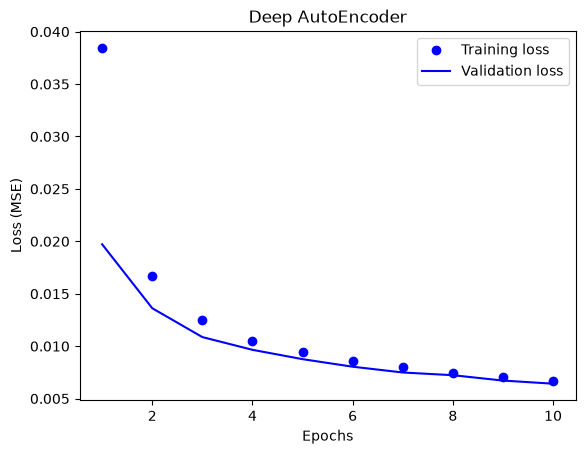

In [6]:
os.makedirs('histories', exist_ok=True)

filename = "deep_ae"
hist_path = f'histories/{filename}.hist'
weights_path = f'histories/{filename}.pt'

if os.path.isfile(hist_path) and os.path.isfile(weights_path):
    with open(hist_path, 'rb') as hist_file:
        history_dict = pickle.load(hist_file)
    autoencoder.load_state_dict(torch.load(weights_path, map_location=DEVICE))
else:
    history_dict = utils.train_autoencoder(autoencoder, optimizer, criterion,
                                     train_loader, test_loader, EPOCHS, DEVICE)
    with open(hist_path, 'wb') as hist_file:
        pickle.dump(history_dict, hist_file)
    torch.save(autoencoder.state_dict(), weights_path)

epochs = range(1, len(history_dict['loss']) + 1)
plt.figure()
plt.plot(epochs, history_dict['loss'], 'bo', label='Training loss')
plt.plot(epochs, history_dict['val_loss'], 'b', label='Validation loss')
plt.title('Deep AutoEncoder')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.legend(loc='upper right')
plt.show()

# VALUTAZIONE

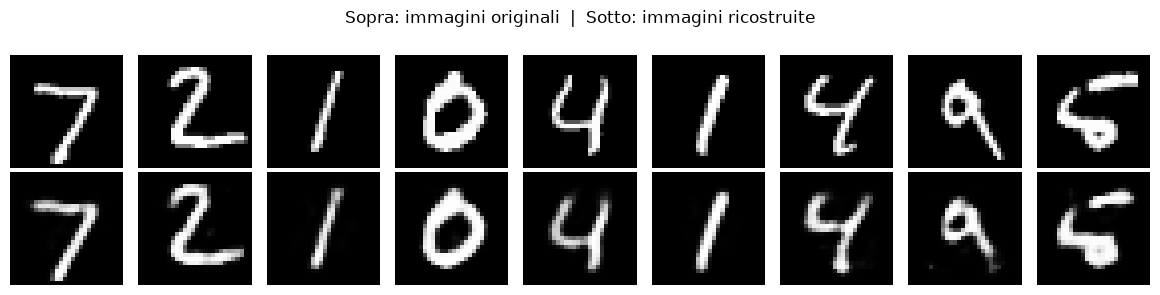

In [7]:
# TEST: ricostruzione di alcune immagini del test set
autoencoder.eval()
x, _ = next(iter(test_loader))
with torch.no_grad():
    x_rec = autoencoder(x.to(DEVICE)).cpu()

n_show = 9
plt.figure(figsize=(1.3 * n_show, 3))
for i in range(n_show):
    plt.subplot(2, n_show, i + 1)
    plt.imshow(x[i].squeeze(), cmap='gray')
    plt.axis('off')
    plt.subplot(2, n_show, n_show + i + 1)
    plt.imshow(x_rec[i].squeeze(), cmap='gray')
    plt.axis('off')
plt.suptitle('Sopra: immagini originali  |  Sotto: immagini ricostruite')
plt.tight_layout()
plt.show()

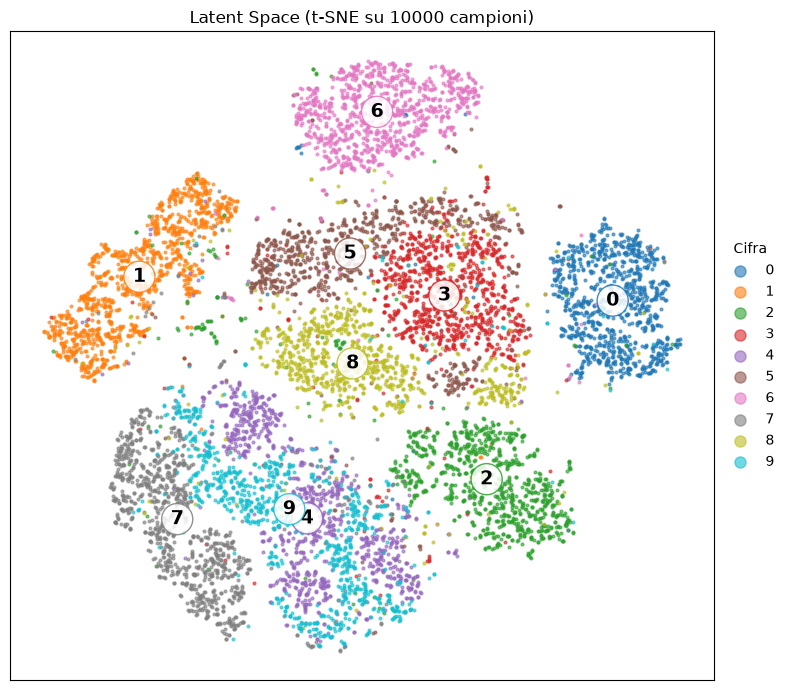

In [8]:
# LATENT SPACE (t-SNE)
n_tsne = 10000
rng = np.random.default_rng(0)
idx = rng.choice(len(train_dataset), size=n_tsne, replace=False)
subset_loader = DataLoader(Subset(train_dataset, idx), batch_size=1024, shuffle=False)

encoder.eval()
codes, labels = [], []
with torch.no_grad():
    for x, y in subset_loader:
        codes.append(encoder(x.to(DEVICE)).cpu())   # codici latenti a H2 = 64 dimensioni
        labels.append(y)
proj = torch.cat(codes).numpy()
labels = torch.cat(labels).numpy()

tsne = TSNE(n_components=2, perplexity=30, init='pca', learning_rate='auto', random_state=0)
emb = tsne.fit_transform(proj)

plt.figure(figsize=(8, 7))
cmap = plt.get_cmap('tab10')
for d in range(10):
    m = labels == d
    plt.scatter(emb[m, 0], emb[m, 1], s=4, alpha=0.6, color=cmap(d), label=str(d))
    cx, cy = np.median(emb[m], axis=0)
    plt.text(cx, cy, str(d), fontsize=14, weight='bold', ha='center', va='center',
             bbox=dict(boxstyle='circle', facecolor='white', edgecolor=cmap(d), alpha=0.85))
plt.legend(title='Cifra', markerscale=4, loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
plt.xticks([])
plt.yticks([])
plt.gca().set_aspect('equal', 'datalim')
plt.title(f'Latent Space (t-SNE su {n_tsne} campioni)')
plt.tight_layout()
plt.show()